# Lab w11: Fitting Forgetting Curves
## CSE5026 Foundation and Frontiers of Cognitive Science

In this lab, we will fit forgetting curve data using mathematical models and compare different models' performance.


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
import pandas as pd

### Objectives
1. Understand the basic principles of Ebbinghaus forgetting curve and Dros forgetting curve;
2. Master the use of mathematical models (such as power function, logarithmic function, exponential function, etc.) to fit forgetting data;
3. Learn to use Python for curve fitting and evaluation;
4. Analyze and compare the fitting performance of different models on forgetting data.

### Background
In 1880, Hermann Ebbinghaus conducted self-experiments using nonsense syllables as memory materials, studied the relationship between memory retention and time, and proposed the famous **forgetting curve**. He used the **savings method** to measure memory retention and attempted to describe the forgetting process with mathematical formulas.
The Dros forgetting curve can be considered as a modern verification of the Ebbinghaus forgetting curve, with stricter experimental subjects, materials, data volume, and statistical methods, while also discovering subtle phenomena not revealed in the Ebbinghaus curve (such as the 24-hour memory "jump").

This assignment provides experimental data from the Ebbinghaus forgetting curve and the Murre & Dros (2015) forgetting curve. Students are asked to try fitting multiple forgetting curve models and compare their fitting performance.

### Model formulas

You need to implement two models: `Power Function` and `Memory Chain Model`, following their formulas: 

1. Power Function Model
$$
Q(t) = (1 + \mu_1 t)^{-a_1}
$$

2. Memory Chain Model (Double Exponential Model)
$$
Q(t) = \mu_1 e^{-a_1 t} + \frac{\mu_1 \mu_2 (e^{-a_2 t} - e^{-a_1 t})}{a_1 - a_2}
$$

Fit the two models on Ebbinghaus's original data and plot the forgeting curves, and compare them with the original Ebbinghaus curve, which is described by the following formula:

Ebbinghaus 1885 Logarithmic Model
$$
Q(t) = \frac{1.84}{(\log_{10} t)^{1.25} + 1.84}
$$

### Assignment Requirements

1. Data Fitting
- Use `curve_fit` function in `scipy.optimize` to fit the parameters of the above three models.
- Record the fitting parameters, residual sum of squares (SSD), coefficient of determination (R²), and other metrics for each model.

2. Model Comparison
- Use **AIC (Akaike Information Criterion)** to compare the goodness of fit of the three models
- Explain which model best describes the forgetting data.

3. Visualization
- Plot the original data points.
- Plot the fitting curves of the three models in the same figure.
- Add legend, axis labels, title, etc.

## Task 1: Fit Ebbinghaus's data

Use the following **Ebbinghaus**'s original data, which is copied from the `For Mathematica` sheet in the `Ebbinghaus Replication Schema and Results - also from Mathematica - V1.7.xlsx` file:

In [ ]:
# Experimental data: time intervals (days) and memory retention rates
time_days = np.array([0.0139, 0.0417, 0.375, 1, 2, 6, 31])  # 20 minutes, 1 hour, 9 hours, 1 day, 2 days, 6 days, 31 days
savings = np.array([0.582, 0.442, 0.358, 0.337, 0.278, 0.254, 0.211])

data_ebbinghaus = pd.DataFrame({
    'T': time_days,
    'Time Interval': ['20min', '1h', '9h', '1d', '2d', '6d', '31d'],
    'Q': savings
})
print("Experimental data:")
print(data_ebbinghaus.to_string(index=False))


Experimental data:
      T Time Interval     Q
 0.0139         20min 0.582
 0.0417            1h 0.442
 0.3750            9h 0.358
 1.0000            1d 0.337
 2.0000            2d 0.278
 6.0000            6d 0.254
31.0000           31d 0.211


First, you need to implement the model formulas in Python expressions, given the parameters passed in.

In [ ]:
def power_function(t, mu1, a1):
    """Power function model"""
    #### START YOUR CODE ####
    # TODO: Power function formula
    formula = None
    #### END YOUR CODE ####
    return formula

def memory_chain_model(t, mu1, a1, mu2, a2):
    """Memory Chain Model (Double exponential model)"""
    #### START YOUR CODE ####
    # TODO: Memory Chain Model formula
    # Hint: should handle the division by zero error by adding a small epsilon value
    formula = None
    #### END YOUR CODE ####
    return formula

def ebbinghaus_log_function(t):
    """Ebbinghaus logarithmic model (constant parameters)"""
    #### START YOUR CODE ####
    # TODO: Ebbinghaus logarithmic model formula
    # Hint: To avoid log(0), we handle the case where t=0 by replacing with a small value
    # Hint: the input time t is in unit days, which needs to be converted to minutes.
    formula = None
    #### END YOUR CODE ####
    return formula


The following cell defines the evaluation functions:

In [29]:
def calculate_ssd(y_true, y_pred):
    """Calculate residual sum of squares"""
    return np.sum((y_true - y_pred) ** 2)

def calculate_r2(y_true, y_pred):
    """Calculate coefficient of determination R²"""
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
    return 1 - (ss_res / ss_tot)

def calculate_aic(n, ssd, k):
    """Calculate AIC value"""
    return n * np.log(ssd / n) + 2 * k

Now, you can use `curve_fit` to fit the models.

The function takes the formula, xdata (`time_days`), ydata (`savings`), and initial parameters as input. The initial guesses in `p0`, the upper and lower bounds `bounds` are provided for you. 

You just need to call `curve_fit` correctly.

In [ ]:
x = data_ebbinghaus['T']
y = data_ebbinghaus['Q']

# 1. Power function model fitting
try:
    #### START YOUR CODE ####
    # TODO: call curve_fit
    params, _ = curve_fit(f = None, xdata = None, ydata = None, 
                                     p0=[1.0, 0.1], bounds=(0, [10, 2]))
    #### END YOUR CODE ####

    y_power = power_function(x, *params)
    ssd_power = calculate_ssd(y, y_power)
    r2_power = calculate_r2(y, y_power)
    aic_power = calculate_aic(len(y), ssd_power, 2)

    print(f"Power function model fitted successfully:")
    print(f"  Parameters: μ1={params[0]:.4f}, a1={params[1]:.4f}")
    print(f"  SSD={ssd_power:.6f}, R²={r2_power:.4f}, AIC={aic_power:.2f}")
except Exception as e:
    print(f"Power function model fitting failed: {e}")

# 2. Double exponential model fitting
try:
    #### START YOUR CODE ####
    # TODO: call curve_fit
    params, _ = curve_fit(f = None, xdata = None, ydata = None, 
                                 p0=[0.5, 0.1, 0.3, 0.01], 
                                 bounds=([0, 0, 0, 0], [2, 1, 2, 1]))
    #### END YOUR CODE ####

    y_mcm = memory_chain_model(x, *params)
    ssd_mcm = calculate_ssd(y, y_mcm)
    r2_mcm = calculate_r2(y, y_mcm)
    aic_mcm = calculate_aic(len(y), ssd_mcm, 4)

    print(f"\nDouble exponential model fitted successfully:")
    print(f"  Parameters: μ1={params[0]:.4f}, a1={params[1]:.4f}, μ2={params[2]:.4f}, a2={params[3]:.4f}")
    print(f"  SSD={ssd_mcm:.6f}, R²={r2_mcm:.4f}, AIC={aic_mcm:.2f}")
except Exception as e:
    print(f"Double exponential model fitting failed: {e}")


# 3. Ebbinghaus logarithmic model (no parameter fitting, direct calculation)
y_ebbinghaus = ebbinghaus_log_function(x)
ssd_ebbinghaus = calculate_ssd(y, y_ebbinghaus)
r2_ebbinghaus = calculate_r2(y, y_ebbinghaus)
aic_ebbinghaus = calculate_aic(len(y), ssd_ebbinghaus, 0)  # No fitting parameters

print(f"\nEbbinghaus logarithmic model:")
print(f"  SSD={ssd_ebbinghaus:.6f}, R²={r2_ebbinghaus:.4f}, AIC={aic_ebbinghaus:.2f}")


Expected output (after completing the code):

Power function model fitted successfully:
  Parameters: μ1=10.0000, a1=0.5443
  SSD=0.337089, R²=-2.5033, AIC=-17.23

Double exponential model fitted successfully:
  Parameters: μ1=0.4995, a1=1.0000, μ2=0.4800, a2=0.0037
  SSD=0.013593, R²=0.8587, AIC=-35.71

Ebbinghaus logarithmic model:
  SSD=0.002402, R²=0.9750, AIC=-55.84


Integrate the above fit and summary functions into one:

In [ ]:
def fit_summary_models(t, savings):
    """Fit the two free models and include the fixed 1885 reference curve."""
    models = {
        "Power Function": (power_function, [1.0, 0.1], (0, [10, 2])),
        "Memory Chain Model": (
            memory_chain_model, [0.5, 0.1, 0.3, 0.01], (0, [2, 1, 2, 1])
        ),
    }

    fits = {}
    for name, (model, start, bounds) in models.items():
        ### START YOUR CODE ###
        # TODO:
        params, _ = None
        ### END YOUR CODE ###
        fits[name] = (model, params)

    fits["Ebbinghaus Logarithmic (fixed)"] = (ebbinghaus_log_function, ())
    
    return fits

And two helper functions for model comparison and visualization:

In [ ]:
def compare_models(t, savings, fits):
    """Score each supplied (model, parameters) pair on the same observations."""
    rows = []
    for name, (model, params) in fits.items():
        predicted = model(t, *params)
        ssd = calculate_ssd(savings, predicted)
        rows.append((name, ssd, calculate_r2(savings, predicted),
                     calculate_aic(len(savings), ssd, len(params)), len(params)))
    table = pd.DataFrame(rows, columns=["Model", "SSD", "R²", "AIC", "Number of Parameters"])

    print(table.to_string(index=False, float_format=lambda value: f"{value:.4f}"))
    best = table.loc[table["AIC"].idxmin()]
    print(f"\nBest model: {best['Model']} (AIC = {best['AIC']:.2f})")
    return table


def plot_forgetting_curves(t, savings, fits, title):
    """Show the observations and model curves for a single task."""
    fig, ax = plt.subplots(figsize=(10, 5.5), layout="constrained")
    ax.scatter(t, savings, s=30, facecolors="none", edgecolors="#4b5563",
               alpha=0.75, label="Observed savings")
    grid = np.geomspace(min(t), max(t), 300)
    for (name, (model, params)), color in zip(fits.items(), ["#0072B2", "#D55E00", "#009E73"]):
        ax.plot(grid, model(grid, *params), color=color, linewidth=2, label=name)

    if min(savings) < 0:
        ax.axhline(0, color="0.5", linewidth=0.8)
    ax.set_xscale("log")
    ax.set_xticks(np.unique(t), ["20 min", "1 h", "9 h", "1 d", "2 d", "6 d", "31 d"])
    ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(xmax=1))
    ax.set(xlabel="Retention interval (log scale)", ylabel="Savings", title=title)
    ax.grid(axis="y", alpha=0.25)
    ax.legend()
    plt.show()

Now, call the integrated functions.

Expected output (after completing the code):

                         Model    SSD      R²      AIC  Number of Parameters
                Power Function 0.3371 -2.5033 -17.2332                     2
            Memory Chain Model 0.0136  0.8587 -35.7086                     4
Ebbinghaus Logarithmic (fixed) 0.0024  0.9750 -55.8417                     0

Best model: Ebbinghaus Logarithmic (fixed) (AIC = -55.84)


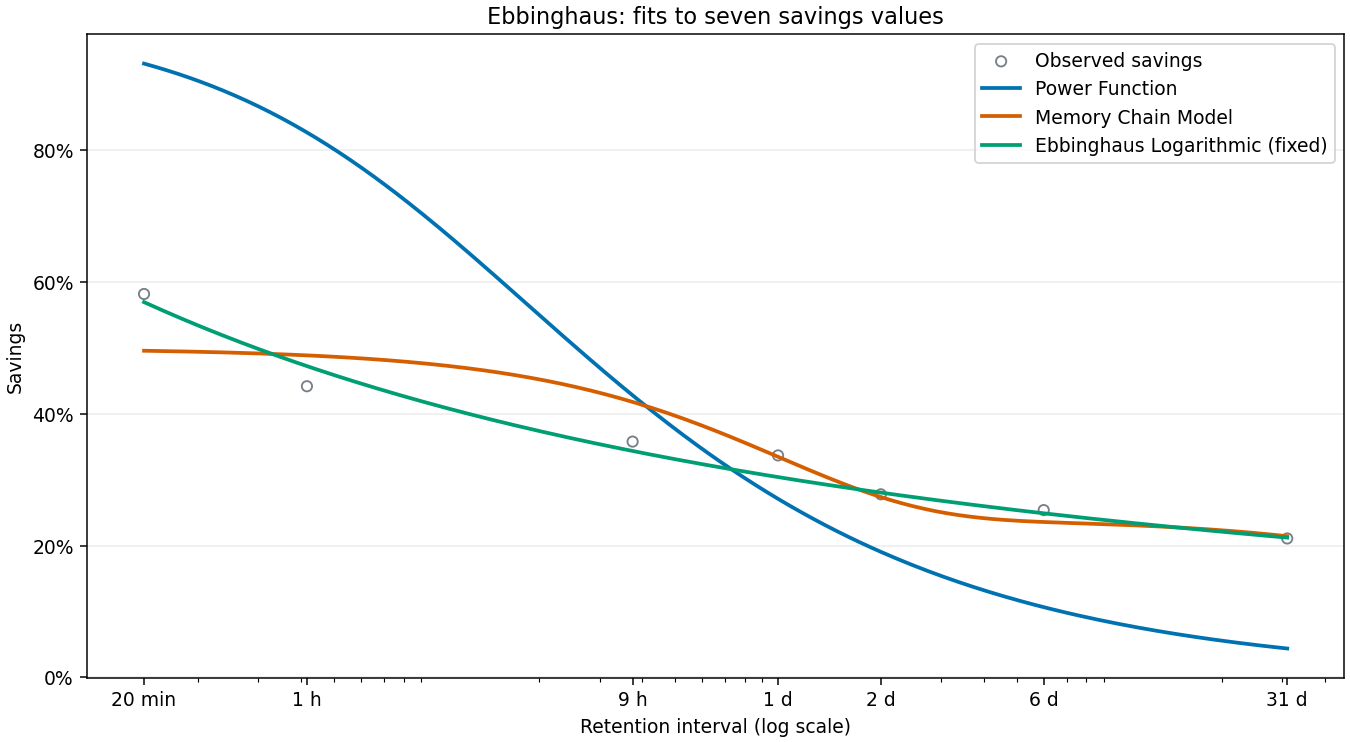

In [ ]:
# Visualize results
time_days = data_ebbinghaus['T'].to_numpy()
savings = data_ebbinghaus['Q'].to_numpy()

### START YOUR CODE ### 
# TODO: 
fits = None
### END YOUR CODE ###

# Compare
compare_models(time_days, savings, fits)

# Plot
plot_forgetting_curves(time_days, savings, fits, "Ebbinghaus: fits to seven savings values")

## Task 2: Fit Dros average savings data

Next, you need to fit the same models on **Dros**'s average savings data (number of repetitions), as follows:


In [ ]:
# Experimental data: time intervals (days) and memory retention rates
time_days = np.array([0.0139, 0.0417, 0.375, 1, 2, 6, 31])  # 20 minutes, 1 hour, 9 hours, 1 day, 2 days, 6 days, 31 days
savings = np.array([0.472, 0.373, 0.276, 0.317, 0.230, 0.168, 0.041])

data_dros = pd.DataFrame({
    'T': time_days,
    'Time Interval': ['20min', '1h', '9h', '1d', '2d', '6d', '31d'],
    'Q': savings
})

print("Dros's experimental data:")
print(data_dros.to_string(index=False))

Dros's experimental data:
      T Time Interval     Q
 0.0139         20min 0.472
 0.0417            1h 0.373
 0.3750            9h 0.276
 1.0000            1d 0.317
 2.0000            2d 0.230
 6.0000            6d 0.168
31.0000           31d 0.041


Fit the three models using the data:

In [ ]:
# Fit the models
t2 = data_dros['T']
q2 = data_dros['Q']

### START YOUR CODE ###
# TODO:
fits2 = None
### END YOUR CODE ###

Expected output (after completing the code):

Power Function: 10, 2
Memory Chain Model: 0.4095, 1, 0.5265, 0.05325
Ebbinghaus Logarithmic (fixed): fixed parameters


Compare and plot:

Expected output (after completing the code):

                         Model    SSD      R²      AIC  Number of Parameters
                Power Function 0.3356 -1.8421 -17.2643                     2
            Memory Chain Model 0.0115  0.9030 -36.9076                     4
Ebbinghaus Logarithmic (fixed) 0.0627  0.4692 -33.0091                     0

Best model: Memory Chain Model (AIC = -36.91)


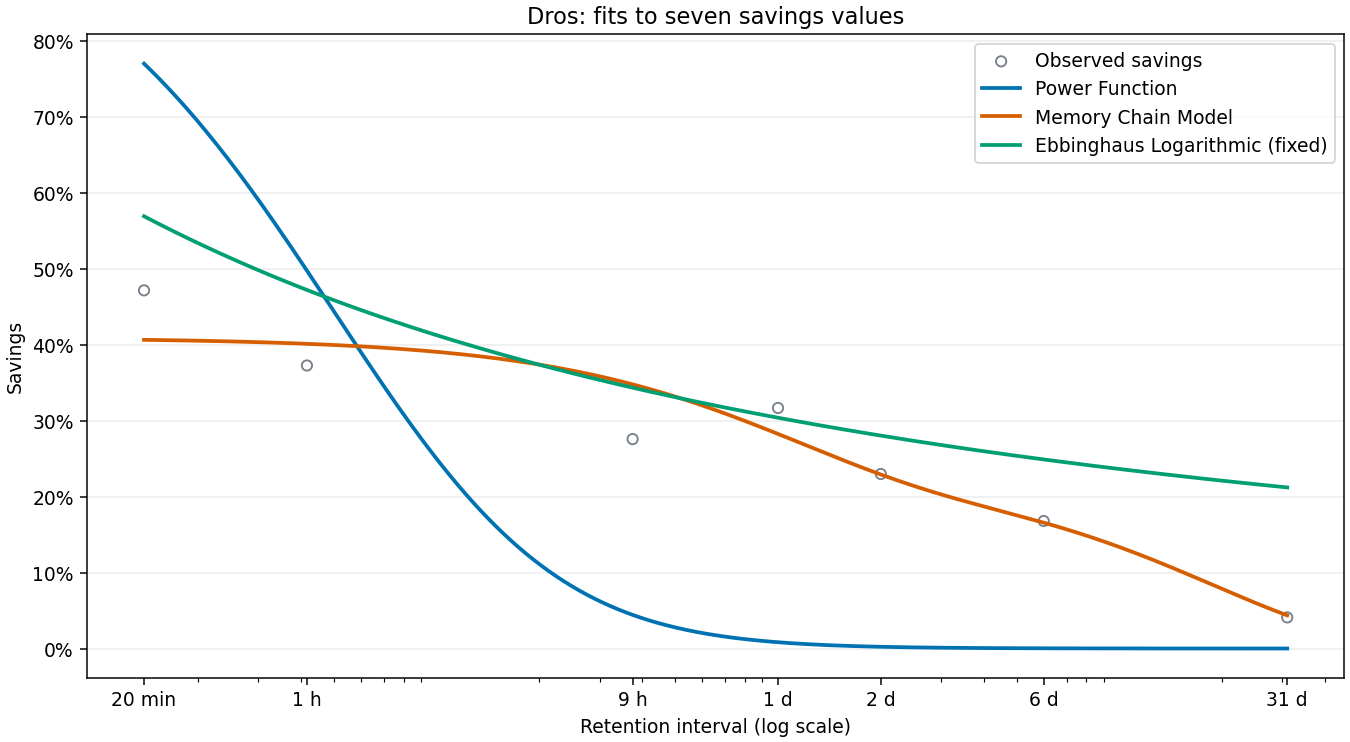

In [ ]:
### START YOUR CODE ###
# TODO:
### END YOUR CODE ###

## Task 3: Fit Dros raw savings data

Lastly, Dros' raw savings data are also provided. Try copying out the data from region `C29` to `I38`, and fit the three models on them.

The data are from 10 Lists (rows) and 7 time intervals (columns).

Since `List10` for `9hours` is missing, there are $7\times 10 - 1 = 69$ data points.

Example fit:

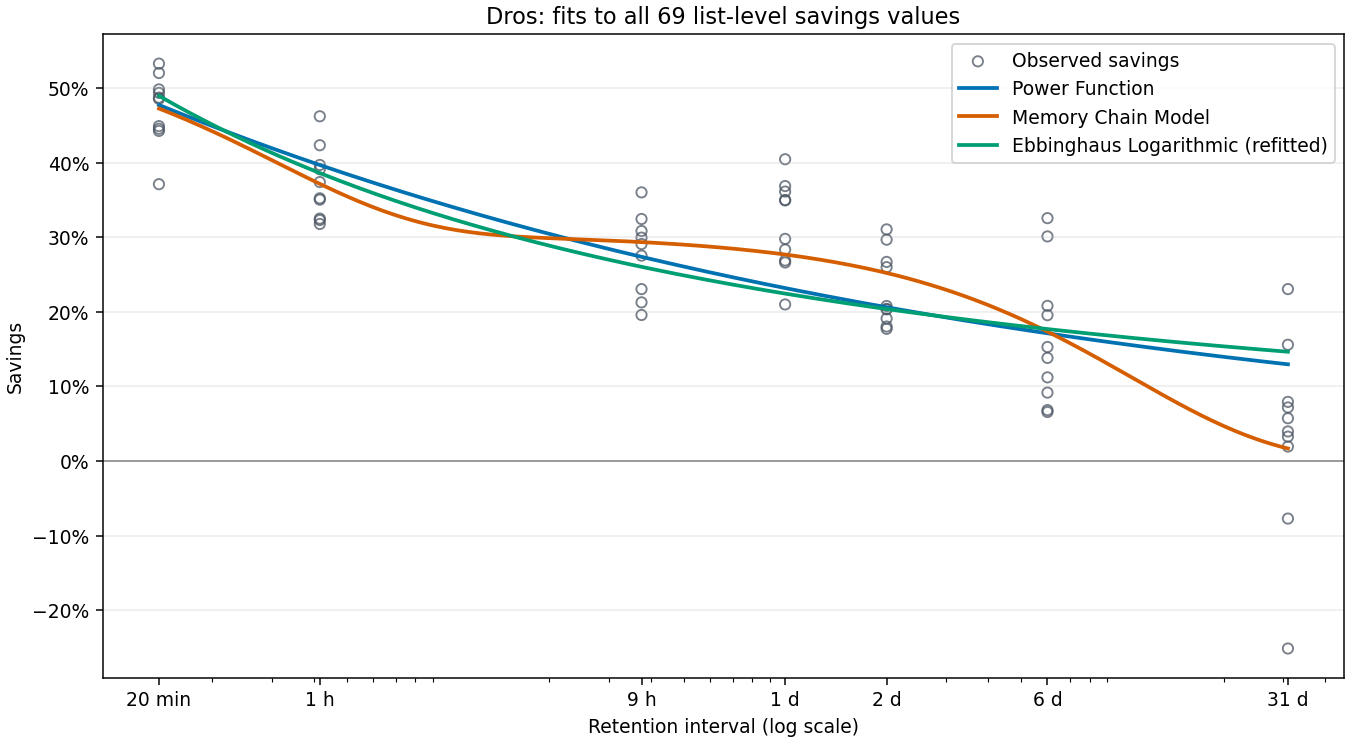

In [ ]:
# You have the freedom to extract data, fit models, and plot the results the way you like.

## References
- Murre, J. M. J., & Dros, J. (2015). Replication and Analysis of Ebbinghaus' Forgetting Curve. *PLOS ONE*, 10(7), e0120644.
- Ebbinghaus, H. (1885). *Über das Gedächtnis*. Leipzig: Duncker.
